# Intro to Machine Learning; Linear Regression Models

In [1]:
import numpy as np
import pandas as pd
from plotnine import ggplot, aes, geom_point, geom_smooth, geom_line, labs, scale_x_continuous, theme_minimal
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

## Music Challenge

Which popular songs from the past will be recognized by future generations, and which will fade into obscurity? The website [The Pudding](https://pudding.cool/) conducts the [Music Challenge](https://pudding.cool/2020/04/music-challenge/) where they ask thousands of people whether they recognize hit songs from the past. We'll look at some of the [data](https://github.com/the-pudding/song-decay-clean/tree/master/src/assets/data) related to the article ["Defining the 90s Music Canon"](https://pudding.cool/2020/07/song-decay/).

The data set at https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv contains 344 songs released in the 1990s. For each song, the proportion of survey respondents who recognized the song is recorded, for both Millennial respondents and Gen Z respondents. Our goal will be to use linear regression to **predict the Gen Z recognition**.

We will try several different linear regression models. Save each of your models with a different name because you will compare them at the end.



0. Read in the data and describe the Gen Z recognition variable.

In [2]:
songs = pd.read_csv("https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv", index_col=0)
print(songs.shape)
print(songs.describe())
songs.head()

(344, 2)
       mean_millennial_recognition  mean_gen_z_recognition
count                   344.000000              344.000000
mean                      0.401364                0.235506
std                       0.265956                0.210541
min                       0.043351                0.019483
25%                       0.178364                0.095589
50%                       0.344978                0.155398
75%                       0.584260                0.303051
max                       0.991851                0.963497


,mean_millennial_recognition,mean_gen_z_recognition
artist_song,,
2 Pac|||California Love,0.517602,0.268378
2Pac|||How Do U Want It,0.209632,0.062439
702|||Where My Girls At?,0.553481,0.244176
Ace Of Base|||All That She Wants,0.830967,0.540097
Ace Of Base|||Don't Turn Around,0.623149,0.372787


1. Use scikit-learn to fit a linear regression model for predicting Gen Z recognition from Millennial recognition.

In [3]:
X = songs[["mean_millennial_recognition"]]  # DataFrame (2-D)
y = songs["mean_gen_z_recognition"]        # Series (1-D)

print(type(X).__name__, X.shape, "|", type(y).__name__, y.shape)

DataFrame (344, 1) | Series (344,)


In [4]:
model_genz = LinearRegression()
model_genz.fit(X, y)
print("intercept:", round(model_genz.intercept_, 4))
print("coef:     ", model_genz.coef_.round(4))
print("R²:       ", round(model_genz.score(X, y), 3))

intercept: -0.0481
coef:      [0.7067]
R²:        0.797


2. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

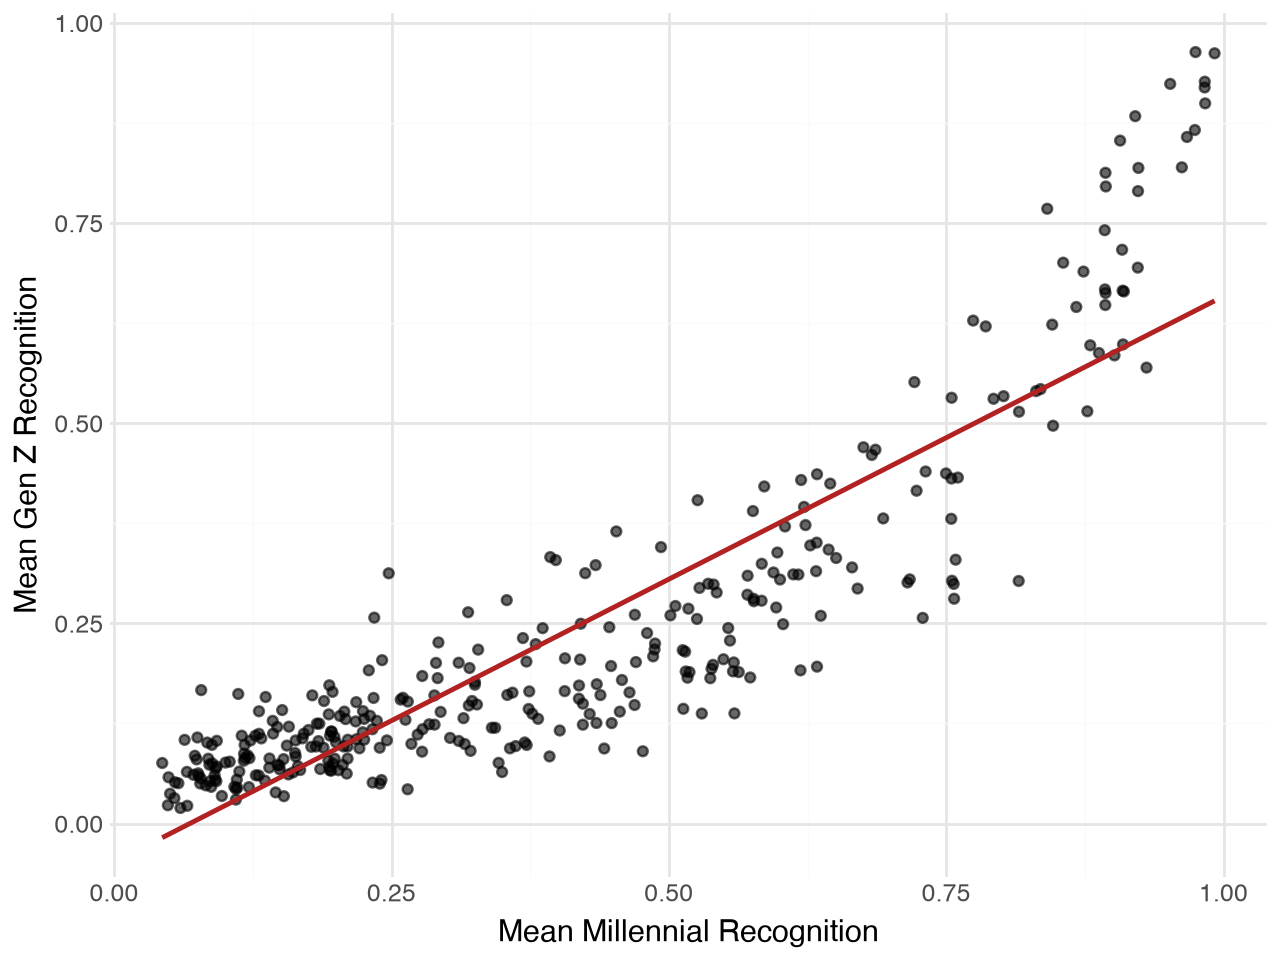

In [5]:
(
    ggplot(
        songs,
        aes(
            x="mean_millennial_recognition",
            y="mean_gen_z_recognition"
        )
    )
    + geom_point(alpha=0.6)
    + geom_smooth(method="lm", se=False, color="firebrick")
    + labs(
        x="Mean Millennial Recognition",
        y="Mean Gen Z Recognition"
    )
    + theme_minimal()
)

3. Explain why you might want to consider taking a log of Gen Z recognition. Then use scikit-learn to fit a linear regression model for predicting log of Gen Z recognition from Millennial recognition.

In [6]:
# Gen Z recognition is positive and strongly right-skewed: many songs have low
# recognition and a few have very high recognition. Taking a log spreads out
# the small values and compresses the large values, which can make the
# relationship more linear and the vertical variability more even.

X = songs[["mean_millennial_recognition"]]
y_log = np.log(songs["mean_gen_z_recognition"])

log_gen_z_model = LinearRegression()
log_gen_z_model.fit(X, y_log)

print("intercept:", round(log_gen_z_model.intercept_, 4))
print("coef:     ", log_gen_z_model.coef_.round(4))
print("R² (log scale):", round(log_gen_z_model.score(X, y_log), 3))

intercept: -2.9083
coef:      [2.7992]
R² (log scale): 0.823


4. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

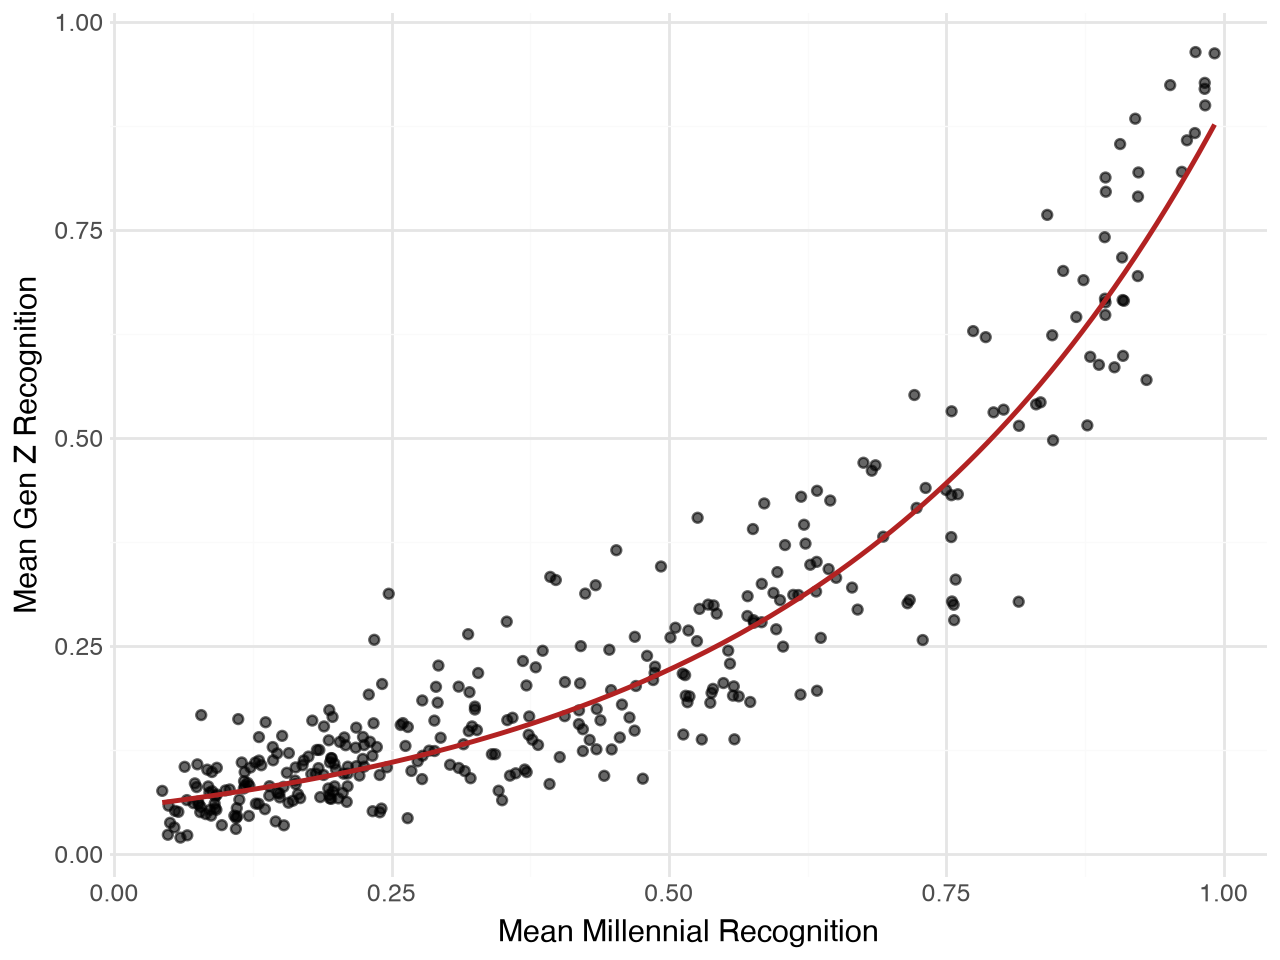

In [7]:
# Predict on a fine grid and transform the predictions back to the original
# recognition scale with exp() before overlaying the fitted curve.
log_curve = pd.DataFrame({
    "mean_millennial_recognition": np.linspace(
        songs["mean_millennial_recognition"].min(),
        songs["mean_millennial_recognition"].max(),
        200
    )
})
log_curve["predicted_gen_z_recognition"] = np.exp(
    log_gen_z_model.predict(log_curve[["mean_millennial_recognition"]])
)

(
    ggplot(
        songs,
        aes(x="mean_millennial_recognition", y="mean_gen_z_recognition")
    )
    + geom_point(alpha=0.6)
    + geom_line(
        data=log_curve,
        mapping=aes(
            x="mean_millennial_recognition",
            y="predicted_gen_z_recognition"
        ),
        color="firebrick",
        size=1
    )
    + labs(
        x="Mean Millennial Recognition",
        y="Mean Gen Z Recognition"
    )
    + theme_minimal()
)

5. Now we'll try a polynomial model for predicting Gen Z recognition from Millennial recognition. Use scikit-learn to fit a model with two features: Millennial recognition and its square.

In [8]:
songs_square = songs.assign(
    millennial_recognition_squared=(
        songs["mean_millennial_recognition"] ** 2
    )
)

X_square = songs_square[[
    "mean_millennial_recognition",
    "millennial_recognition_squared"
]]
y = songs_square["mean_gen_z_recognition"]

square_model = LinearRegression()
square_model.fit(X_square, y)

print("R²:", round(square_model.score(X_square, y), 3))

R²: 0.898


In [9]:
square_model.coef_, square_model.intercept_

(array([-0.27263527,  1.02072241]), np.float64(0.10851294576257645))

6. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model.

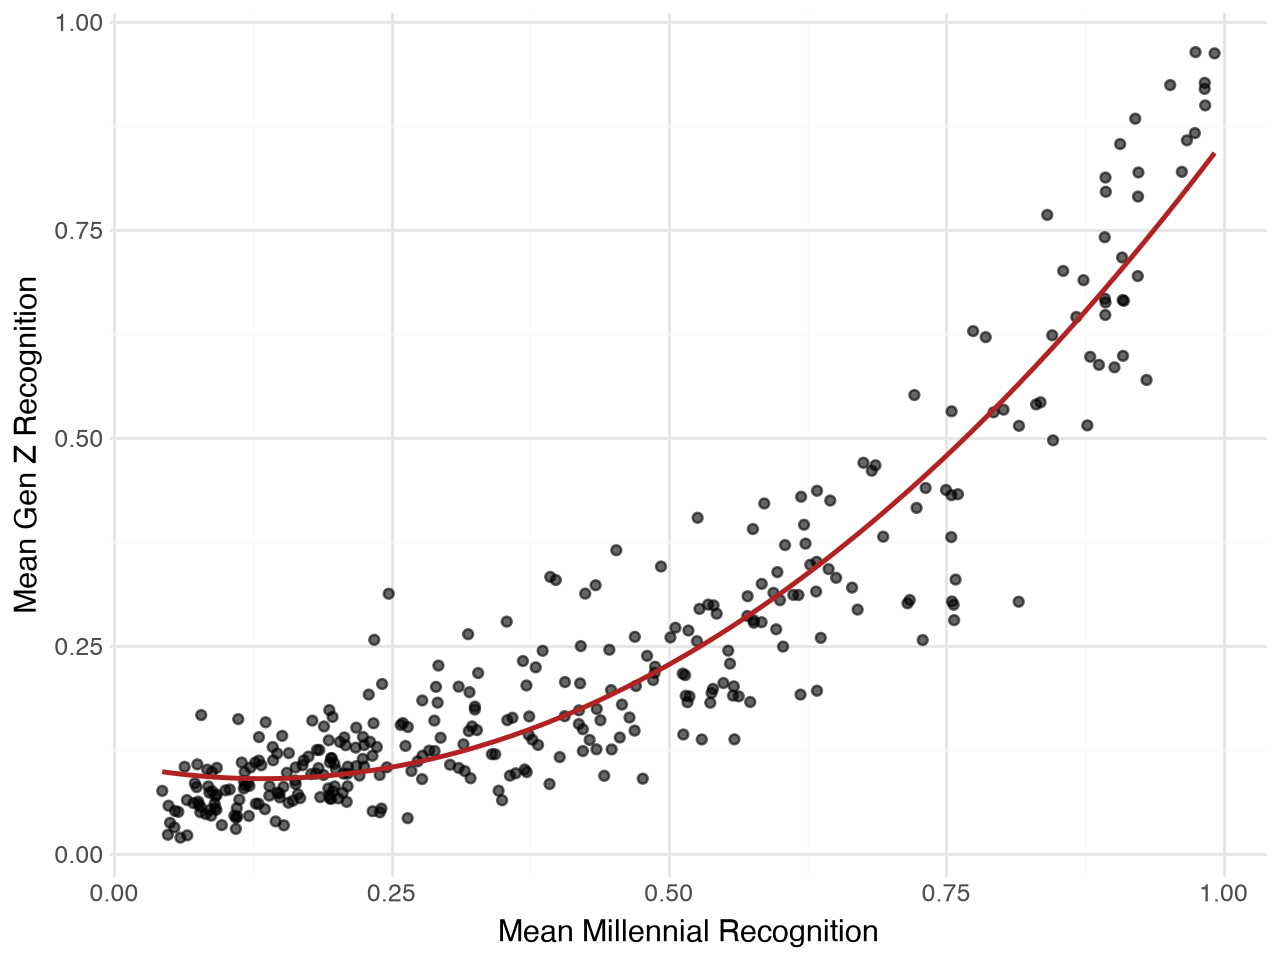

In [10]:
square_curve = pd.DataFrame({
    "mean_millennial_recognition": np.linspace(
        songs["mean_millennial_recognition"].min(),
        songs["mean_millennial_recognition"].max(),
        200
    )
})
square_curve["millennial_recognition_squared"] = (
    square_curve["mean_millennial_recognition"] ** 2
)
square_curve["predicted_gen_z_recognition"] = square_model.predict(
    square_curve[X_square.columns]
)

(
    ggplot(
        songs,
        aes(x="mean_millennial_recognition", y="mean_gen_z_recognition")
    )
    + geom_point(alpha=0.6)
    + geom_line(
        data=square_curve,
        mapping=aes(
            x="mean_millennial_recognition",
            y="predicted_gen_z_recognition"
        ),
        color="firebrick",
        size=1
    )
    + labs(
        x="Mean Millennial Recognition",
        y="Mean Gen Z Recognition"
    )
    + theme_minimal()
)

7. Choose one of your favorite songs that is in the data set. Use each model to predict the Gen Z recognition for the song. Which model gives the best prediction?

In [11]:
# One favorite in the data set: Britney Spears, "...Baby One More Time"
favorite_name = "Britney Spears|||..Baby One More Time"
favorite_song = songs.loc[[favorite_name]]
actual_recognition = favorite_song["mean_gen_z_recognition"].iloc[0]

favorite_square = favorite_song[["mean_millennial_recognition"]].copy()
favorite_square["millennial_recognition_squared"] = (
    favorite_square["mean_millennial_recognition"] ** 2
)

favorite_predictions = pd.Series(
    {
        "ordinary linear": model_genz.predict(
            favorite_song[["mean_millennial_recognition"]]
        )[0],
        "log-target": np.exp(
            log_gen_z_model.predict(
                favorite_song[["mean_millennial_recognition"]]
            )[0]
        ),
        "quadratic": square_model.predict(
            favorite_square[X_square.columns]
        )[0]
    },
    name="prediction"
).to_frame()

favorite_predictions["actual"] = actual_recognition
favorite_predictions["absolute_error"] = abs(
    favorite_predictions["prediction"] - actual_recognition
)

print(favorite_name)
display(favorite_predictions.sort_values("absolute_error"))
print(
    "Best prediction for this song:",
    favorite_predictions["absolute_error"].idxmin()
)

Britney Spears|||..Baby One More Time


,prediction,actual,absolute_error
log-target,0.876399,0.96196,0.085561
quadratic,0.842254,0.96196,0.119707
ordinary linear,0.652822,0.96196,0.309138


Best prediction for this song: log-target


8. The song "Smells Like Teen Spirit" by Nirvana is inexplicably not included in the data set. Suppose the Millenial recognition of this song is 0.7. Use each model to predict the Gen Z recognition for this song. Which model gives the best prediction?

In [12]:
teen_spirit = pd.DataFrame({
    "mean_millennial_recognition": [0.7]
})
teen_spirit_square = teen_spirit.copy()
teen_spirit_square["millennial_recognition_squared"] = 0.7 ** 2

teen_spirit_predictions = pd.Series(
    {
        "ordinary linear": model_genz.predict(teen_spirit)[0],
        "log-target": np.exp(log_gen_z_model.predict(teen_spirit)[0]),
        "quadratic": square_model.predict(
            teen_spirit_square[X_square.columns]
        )[0]
    },
    name="predicted_gen_z_recognition"
).to_frame()

# Compare original-scale training RMSE as one piece of evidence about the
# models. A held-out test set or cross-validation would be a better comparison.
teen_spirit_predictions["training_RMSE"] = [
    root_mean_squared_error(y, model_genz.predict(X)),
    root_mean_squared_error(y, np.exp(log_gen_z_model.predict(X))),
    root_mean_squared_error(y, square_model.predict(X_square))
]

display(teen_spirit_predictions.sort_values("training_RMSE"))
print(
    "The actual Gen Z recognition is unknown, so we cannot know which",
    "prediction is closest. Based on training RMSE, the log-target model",
    "is the strongest of these three, but test data would give better evidence."
)

,predicted_gen_z_recognition,training_RMSE
log-target,0.387177,0.064089
quadratic,0.417822,0.067307
ordinary linear,0.446562,0.094724


The actual Gen Z recognition is unknown, so we cannot know which prediction is closest. Based on training RMSE, the log-target model is the strongest of these three, but test data would give better evidence.


## Categorical Predictors (FEV data)

Do non-smokers have better lungs than smokers? One measure of lung function is forced expiratory volume (FEV), the amount of air (in liters) an individual can exhale in the first second of forceful breath.  Larger values of FEV are indicative of better functioning lungs. In a study, FEV was measured for a group of 654 subjects, along with whether or not they smoked and other variables.

In [13]:
df_fev = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/FEV.csv")

df_fev

,ID,Smoking status,FEV,Height,Age (months)
0,201,non-smoker,2.884,69.0,132
1,202,non-smoker,2.328,64.0,120
2,301,non-smoker,1.708,57.0,108
3,341,non-smoker,3.381,63.0,172
4,351,non-smoker,2.170,58.0,130
...,...,...,...,...,...
649,83841,non-smoker,2.115,50.0,58
650,83901,non-smoker,2.328,60.0,98
651,83951,smoker,3.069,65.0,130
652,83952,non-smoker,1.495,57.0,85


1\. First fit a regression model with a single predictor: Smoking status. Since this variable is categorical you need to "dummify" it before fitting the model.

In [14]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer

X_smoking = df_fev[["Smoking status"]]
y_fev = df_fev["FEV"]

smoking_encoder = OneHotEncoder()
X_smoking_dummies = smoking_encoder.fit_transform(X_smoking)

smoking_model = LinearRegression()
smoking_model.fit(X_smoking_dummies, y_fev)

print("categories:", smoking_encoder.categories_[0])
print("intercept:", round(smoking_model.intercept_, 4))
print("coefficients:", smoking_model.coef_.round(4))

categories: ['non-smoker' 'smoker']
intercept: 2.9215
coefficients: [-0.3554  0.3554]


2\. What are the predictions from this model? How could we have known that those would be the predictions?

In [15]:
smoking_levels = pd.DataFrame({
    "Smoking status": smoking_encoder.categories_[0]
})

smoking_predictions = pd.Series(
    smoking_model.predict(smoking_encoder.transform(smoking_levels)),
    index=smoking_levels["Smoking status"],
    name="model prediction"
)

comparison = pd.concat(
    [
        smoking_predictions,
        df_fev.groupby("Smoking status")["FEV"].mean().rename("group mean")
    ],
    axis=1
)
comparison

,model prediction,group mean
Smoking status,,
non-smoker,2.566143,2.566143
smoker,3.276862,3.276862


3\. Look at the results for the previous parts. What do you notice? Is this what you expected? Remember: larger FEV means better lungs - who tends to have larger FEV, smokers or non-smokers?

The model predicts about **2.566 liters for non-smokers** and **3.277 liters for smokers**. These predictions equal the mean FEV within each smoking-status group, which is what a linear regression with only one categorical predictor produces.

This says that smokers in this sample tend to have higher FEV than non-smokers. That is surprising if we interpret the difference as a causal effect of smoking, but this one-predictor model does not adjust for other differences between the groups.

4\. Suggest some explanations for why smokers tend to have *higher* FEV than non-smokers?

Smoking status is confounded with age and body size in this sample. The smokers are older on average (about 163 months versus 114 months) and taller on average (about 66 inches versus 61 inches). Older and taller subjects generally have larger lungs and therefore higher FEV. The unadjusted model mixes these age and size differences with smoking status, so it should not be interpreted as evidence that smoking improves lung function.

5\. Fit a linear regression model with two predictors: smoking status and Age (and no interaction).

In [16]:
# One-hot encode smoking status, pass Age through unchanged, and then fit
# one additive linear model. With no interaction, both groups have the same
# fitted age slope but different intercepts.
fev_transformer = make_column_transformer(
    (OneHotEncoder(), ["Smoking status"]),
    remainder="passthrough"
)

smoking_age_model = make_pipeline(
    fev_transformer,
    LinearRegression()
)

X_fev_age = df_fev[["Smoking status", "Age (months)"]]
smoking_age_model.fit(X_fev_age, y_fev)

print("R²:", round(smoking_age_model.score(X_fev_age, y_fev), 3))
print(
    "RMSE:",
    round(root_mean_squared_error(y_fev, smoking_age_model.predict(X_fev_age)), 3)
)

R²: 0.576
RMSE: 0.564


6\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

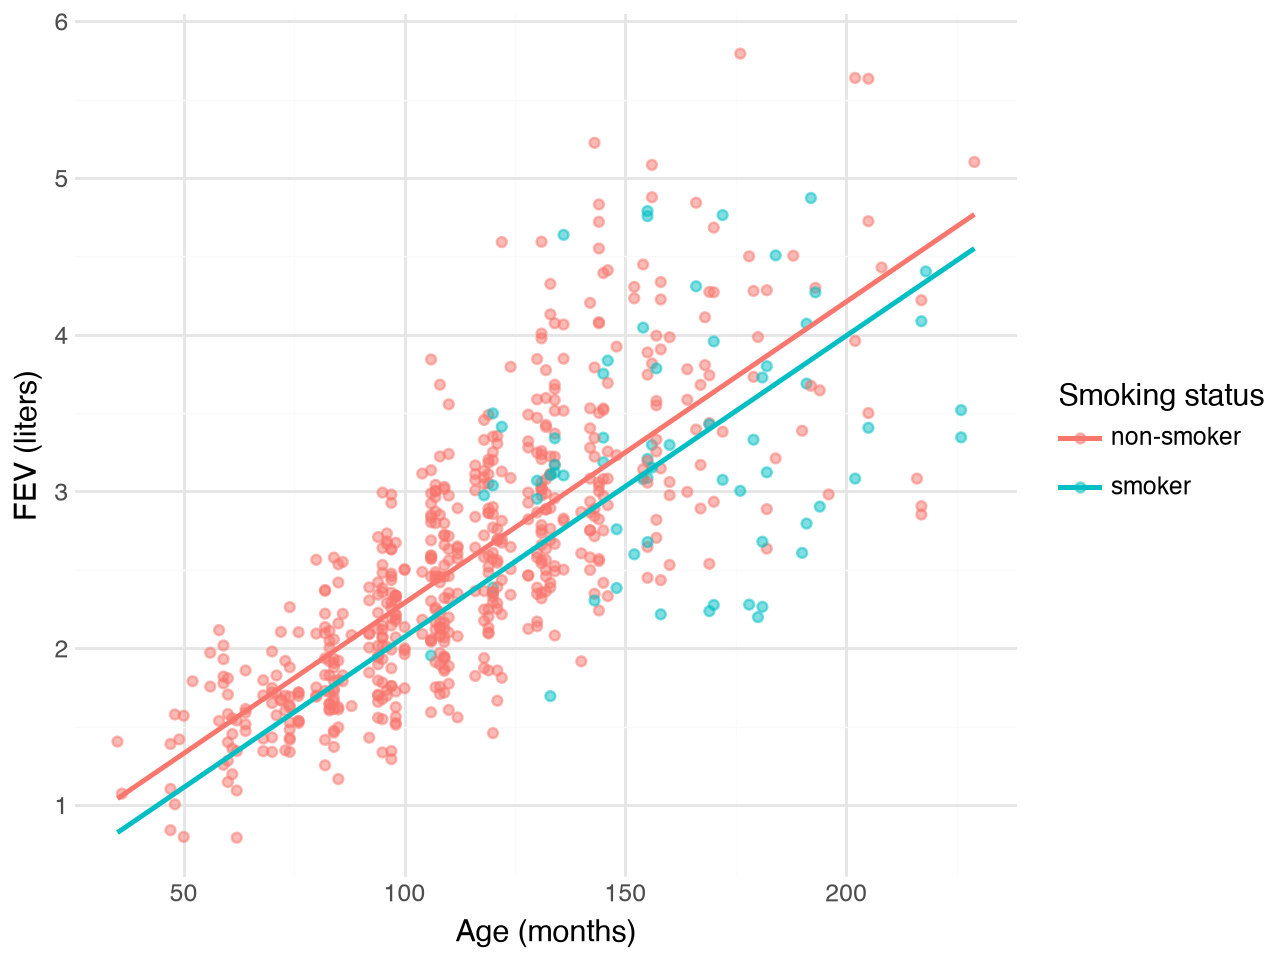

In [17]:
age_values = np.linspace(
    df_fev["Age (months)"].min(),
    df_fev["Age (months)"].max(),
    200
)
fev_parallel_lines = pd.DataFrame({
    "Age (months)": np.tile(age_values, 2),
    "Smoking status": np.repeat(smoking_encoder.categories_[0], len(age_values))
})
fev_parallel_lines["predicted_FEV"] = smoking_age_model.predict(
    fev_parallel_lines[["Smoking status", "Age (months)"]]
)

(
    ggplot(
        df_fev,
        aes(x="Age (months)", y="FEV", color="Smoking status")
    )
    + geom_point(alpha=0.5)
    + geom_line(
        data=fev_parallel_lines,
        mapping=aes(
            x="Age (months)",
            y="predicted_FEV",
            color="Smoking status"
        ),
        size=1
    )
    + labs(x="Age (months)", y="FEV (liters)")
    + theme_minimal()
)

7\. Fit a linear regression model with predictors smoking status, Age, and their interaction.

In [18]:
# Create a 0/1 dummy and multiply it by age to form the interaction.
df_fev_interaction = df_fev.copy()
df_fev_interaction["is_smoker"] = (
    df_fev_interaction["Smoking status"] == "smoker"
).astype(int)
df_fev_interaction["age_x_smoker"] = (
    df_fev_interaction["Age (months)"]
    * df_fev_interaction["is_smoker"]
)

interaction_features = [
    "is_smoker",
    "Age (months)",
    "age_x_smoker"
]
smoking_age_interaction_model = LinearRegression()
smoking_age_interaction_model.fit(
    df_fev_interaction[interaction_features],
    y_fev
)

interaction_predictions = smoking_age_interaction_model.predict(
    df_fev_interaction[interaction_features]
)
print(
    "R²:",
    round(
        smoking_age_interaction_model.score(
            df_fev_interaction[interaction_features], y_fev
        ),
        3
    )
)
print("RMSE:", round(root_mean_squared_error(y_fev, interaction_predictions), 3))

R²: 0.592
RMSE: 0.553


8\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

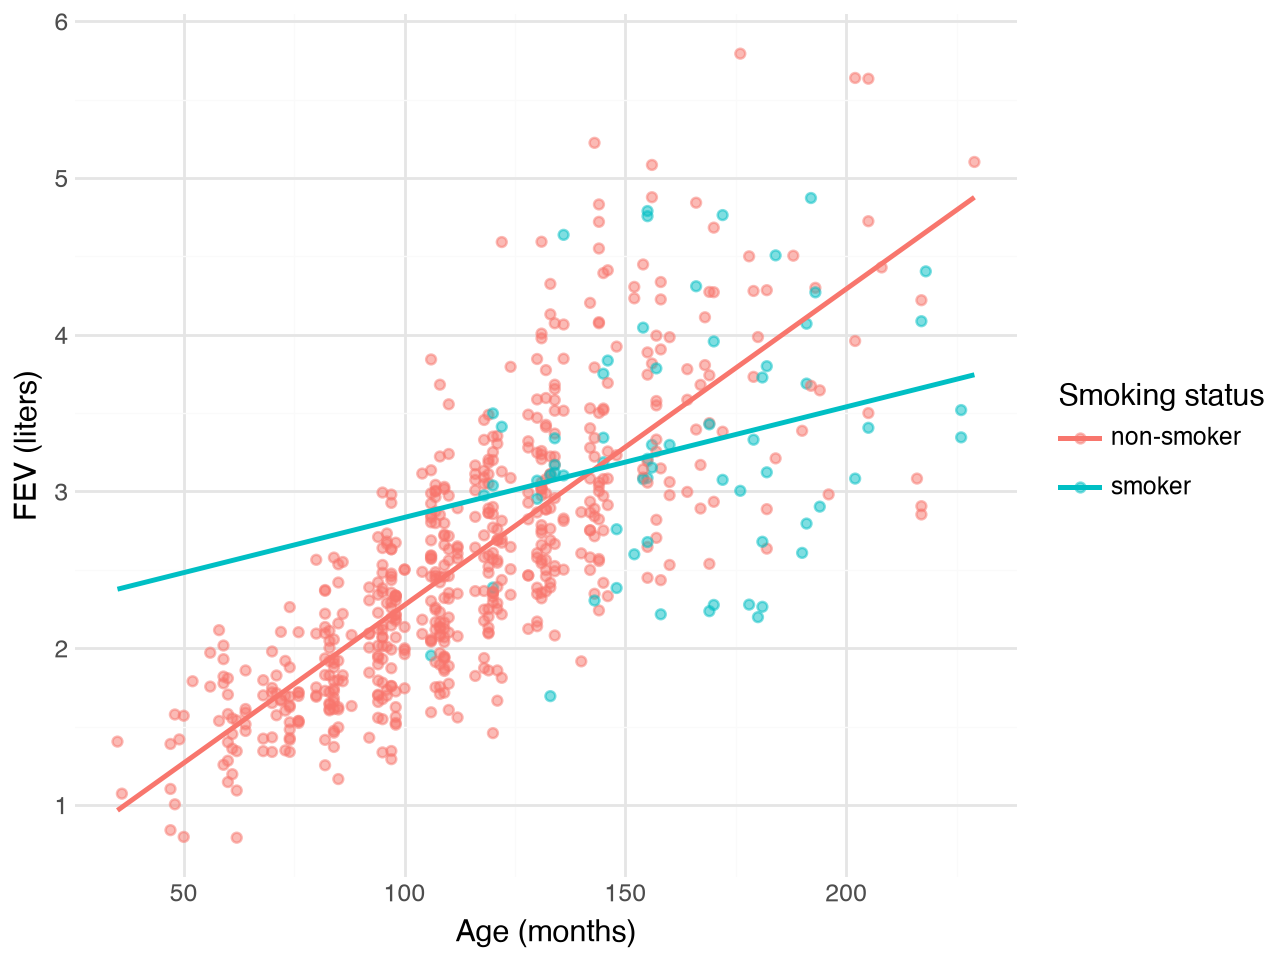

In [19]:
fev_interaction_lines = fev_parallel_lines.copy()
fev_interaction_lines["is_smoker"] = (
    fev_interaction_lines["Smoking status"] == "smoker"
).astype(int)
fev_interaction_lines["age_x_smoker"] = (
    fev_interaction_lines["Age (months)"]
    * fev_interaction_lines["is_smoker"]
)
fev_interaction_lines["predicted_FEV"] = (
    smoking_age_interaction_model.predict(
        fev_interaction_lines[interaction_features]
    )
)

(
    ggplot(
        df_fev,
        aes(x="Age (months)", y="FEV", color="Smoking status")
    )
    + geom_point(alpha=0.5)
    + geom_line(
        data=fev_interaction_lines,
        mapping=aes(
            x="Age (months)",
            y="predicted_FEV",
            color="Smoking status"
        ),
        size=1
    )
    + labs(x="Age (months)", y="FEV (liters)")
    + theme_minimal()
)

9\. Compare the models. Which do you think is "best"? Why? How could you investigate?

The **age-by-smoking interaction model** fits these data somewhat better. Its training $R^2$ is about 0.592 instead of 0.576, and its training RMSE is about 0.553 liters instead of 0.564 liters. It also allows the relationship between age and FEV to have different slopes for smokers and non-smokers, which matches the plotted pattern better than forcing parallel lines.

However, training performance alone is not enough to prove that it will predict new subjects better. I would compare the models on a held-out test set or with cross-validation, using a metric such as RMSE. Because the improvement is modest and the interaction model is more complex, I would keep the interaction only if its test or cross-validation performance is consistently better.